# Kaudulla Reservoir 7-Day Storage Forecast

This notebook predicts the effective water storage (in acre-feet) of Kaudulla Reservoir seven calendar days ahead using daily records from Sri Lanka's Irrigation Department (via Macro Lab).

## 1. Loading the Dataset
Upload the CSV file and load it into a pandas DataFrame with the `period` column parsed as dates.


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving LK.WEATHER.RESERVOIR.KAUDULLA.EFFECTIVE_STORAGE.D.csv to LK.WEATHER.RESERVOIR.KAUDULLA.EFFECTIVE_STORAGE.D.csv


In [ ]:
import pandas as pd

filename = next(iter(uploaded))
data = pd.read_csv(filename, comment="#", parse_dates=["period"])

print(data.shape)
data.head()

(2058, 3)


,period,value,status
0,2020-10-01,30250,NaN
1,2020-10-02,30250,NaN
2,2020-10-03,30250,NaN
3,2020-10-04,34250,NaN
4,2020-10-05,35000,NaN


## 2. Checking Missing Values and Missing Dates
All 2,058 rows in `status` are `NaN`, while `period` and `value` have no missing entries. Next, check for missing calendar dates between `2020-10-01` and `2026-11-20`, since missing dates mean shifting by 7 rows does not correspond to 7 calendar days.


In [ ]:
data.isna().sum()

,0
period,0
value,0
status,2058


In [ ]:
all_days = pd.date_range(start=data["period"].min(), end=data["period"].max(), freq="D")
missing_days = all_days.difference(data["period"])

print(len(missing_days))

184


In [ ]:
print(missing_days.year.value_counts().sort_index())

2021    183
2024      1
Name: count, dtype: int64


In [ ]:
missing_2021 = missing_days[missing_days.year == 2021]

print("First missing day:", missing_2021.min().date())
print("Last missing day:", missing_2021.max().date())

First missing day: 2021-04-01
Last missing day: 2021-09-30


## 3. Aligning the 7-Calendar-Day Target
There are 184 missing calendar days (183 days from `2021-04-01` to `2021-09-30`, and 1 day in 2024). To avoid aligning across missing dates, `target_7d` is constructed by adding `pd.Timedelta(days=7)` to `period` and looking up the storage on that exact date.


In [ ]:
storage_by_date = data.set_index("period")["value"]
target_dates = data["period"] + pd.Timedelta(days=7)
data["target_7d"] = target_dates.map(storage_by_date)

print(data.loc[data["period"] == "2021-03-31", ["period", "value", "target_7d"]])

        period  value  target_7d
181 2021-03-31  98900        NaN


In [9]:
dates_to_check = ["2026-11-13", "2026-11-20"]
columns_to_show = ["period", "value", "target_7d"]

data.loc[data["period"].isin(dates_to_check), columns_to_show]

/tmp/ipykernel_564/3851404781.py:4: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  data.loc[data["period"].isin(dates_to_check), columns_to_show]


,period,value,target_7d
2050,2026-11-13,48400,45400.0
2057,2026-11-20,45400,NaN


In [11]:
dates_to_check = pd.to_datetime(["2026-11-13", "2026-11-20"])

## 4. Simple Baseline
A persistence baseline is defined where the 7-day forecast equals today's storage (`baseline_7d = value`), evaluated using Mean Absolute Error (MAE).


In [12]:
data["baseline_7d"] = data["value"]

data.loc[data["period"] == "2026-11-13", ["period", "baseline_7d", "target_7d"]]

,period,baseline_7d,target_7d
2050,2026-11-13,48400,45400.0


In [13]:
data["absolute_error"] = (data["baseline_7d"] - data["target_7d"]).abs()

data[["period", "baseline_7d", "target_7d", "absolute_error"]].head()

,period,baseline_7d,target_7d,absolute_error
0,2020-10-01,30250,37000.0,6750.0
1,2020-10-02,30250,39700.0,9450.0
2,2020-10-03,30250,39700.0,9450.0
3,2020-10-04,34250,39700.0,5450.0
4,2020-10-05,35000,40900.0,5900.0


In [15]:
baseline_mae = data["absolute_error"].mean()
print(f"Baseline MAE: {baseline_mae:,.1f} acre-feet")

Baseline MAE: 3,870.1 acre-feet


## 5. Features and Chronological Train/Test Split
A second feature, `change_past_7d` (today's storage minus storage 7 calendar days ago), is added. To preserve chronological order, rows from `2026-01-01` onward form `test` (317 rows), and earlier rows whose target date is before `2026-01-01` form `train` (1,704 rows).


In [16]:
past_dates = data["period"] - pd.Timedelta(days=7)
data["storage_7d_ago"] = past_dates.map(storage_by_date)
data["change_past_7d"] = data["value"] - data["storage_7d_ago"]

data.loc[data["period"] == "2020-10-08",
         ["period", "storage_7d_ago", "value", "change_past_7d"]]

,period,storage_7d_ago,value,change_past_7d
7,2020-10-08,30250.0,37000,6750.0


In [17]:
features = ["value", "change_past_7d"]
target = "target_7d"

model_data = data.dropna(subset=features + [target]).copy()
print("Usable examples:", len(model_data))

Usable examples: 2028


In [18]:
cutoff = pd.Timestamp("2026-01-01")
target_dates = model_data["period"] + pd.Timedelta(days=7)

train = model_data.loc[target_dates < cutoff].copy()
test = model_data.loc[model_data["period"] >= cutoff].copy()

print("Training examples:", len(train))
print("Test examples:", len(test))

Training examples: 1704
Test examples: 317


## 6. Random Forest and Tuning `max_depth`
An initial 100-tree `RandomForestRegressor` is trained and checked on the 2026 test set (`2,723.9` acre-feet MAE). Next, `train` is split chronologically into `fit_data` (1,339 rows) and `validation` (2025, 358 rows) to tune `max_depth` across `[3, 8, None]`, where `max_depth = 8` gives the lowest validation MAE (`4,479.1` acre-feet).


In [19]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(train[features], train[target])

print("Trees trained:", len(forest.estimators_))

Trees trained: 100


In [20]:
from sklearn.metrics import mean_absolute_error

forest_predictions = forest.predict(test[features])

baseline_mae_test = mean_absolute_error(test[target], test["baseline_7d"])
forest_mae_test = mean_absolute_error(test[target], forest_predictions)

print(f"Baseline test MAE:      {baseline_mae_test:,.1f} acre-feet")
print(f"Random Forest test MAE: {forest_mae_test:,.1f} acre-feet")

Baseline test MAE:      3,129.1 acre-feet
Random Forest test MAE: 2,723.9 acre-feet


In [21]:
validation_start = pd.Timestamp("2025-01-01")
train_target_dates = train["period"] + pd.Timedelta(days=7)

fit_data = train.loc[train_target_dates < validation_start].copy()
validation = train.loc[train["period"] >= validation_start].copy()

print("Examples for fitting:", len(fit_data))
print("Examples for validation:", len(validation))

Examples for fitting: 1339
Examples for validation: 358


In [22]:
for depth in [3, 8]:
    candidate = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )
    candidate.fit(fit_data[features], fit_data[target])

    predictions = candidate.predict(validation[features])
    mae = mean_absolute_error(validation[target], predictions)

    print(f"Depth {depth}: validation MAE = {mae:,.1f} acre-feet")

Depth 3: validation MAE = 4,939.2 acre-feet
Depth 8: validation MAE = 4,479.1 acre-feet


In [23]:
%pip -q install xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

def make_forest(depth):
    return RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=2
    )

depth_scores = {}

for depth in [3, 8, None]:
    model = make_forest(depth)
    model.fit(fit_data[features], fit_data[target])
    predictions = model.predict(validation[features])
    depth_scores[depth] = mean_absolute_error(validation[target], predictions)

for depth, score in depth_scores.items():
    print(f"Depth {str(depth):>4} | validation MAE = {score:,.1f} acre-feet")

best_depth = min(depth_scores, key=depth_scores.get)
print("Selected depth:", best_depth)

Depth    3 | validation MAE = 4,939.2 acre-feet
Depth    8 | validation MAE = 4,479.1 acre-feet
Depth None | validation MAE = 4,709.1 acre-feet
Selected depth: 8


## 7. Comparing Boosting, Stacking, and Hybrid Models
Six models are compared against the baseline: Random Forest (`max_depth=8`), XGBoost, LightGBM, CatBoost, a `StackingRegressor` (Random Forest + XGBoost with a Ridge final estimator trained on the last year of `fit_data`), and a hybrid `RF + ANN` (`VotingRegressor` combining Random Forest and a scaled `MLPRegressor`). Note that `MLPRegressor` reached its `max_iter=1000` limit (`ConvergenceWarning`) during validation fitting, which is a limitation of the hybrid result.


In [ ]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import StackingRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_xgb():
    return XGBRegressor(
        n_estimators=150, max_depth=3, learning_rate=0.05,
        objective="reg:squarederror", random_state=42, n_jobs=2
    )

def make_ann():
    # Scale the inputs and output because storage is measured in large numbers.
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            MLPRegressor(
                hidden_layer_sizes=(16, 8),
                solver="lbfgs",
                max_iter=1000,
                random_state=42
            )
        ),
        transformer=StandardScaler()
    )

In [ ]:
def fit_stacking(frame):
    # The final year inside this training frame teaches the combining model.
    split_date = frame["period"].max() - pd.Timedelta(days=365)
    answer_dates = frame["period"] + pd.Timedelta(days=7)

    early = frame.loc[answer_dates < split_date]
    later = frame.loc[frame["period"] >= split_date]

    forest = make_forest(best_depth).fit(early[features], early[target])
    boost = make_xgb().fit(early[features], early[target])

    stack = StackingRegressor(
        estimators=[("forest", forest), ("boost", boost)],
        final_estimator=make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        cv="prefit"
    )
    stack.fit(later[features], later[target])
    return stack

In [ ]:
def fit_models(frame):
    models = {
        "Random Forest": make_forest(best_depth),
        "XGBoost": make_xgb(),
        "LightGBM": LGBMRegressor(
            n_estimators=150, num_leaves=15, learning_rate=0.05,
            random_state=42, verbosity=-1, n_jobs=2
        ),
        "CatBoost": CatBoostRegressor(
            iterations=150, depth=4, learning_rate=0.05,
            random_seed=42, verbose=False, thread_count=2,
            allow_writing_files=False
        ),
        "RF + ANN": VotingRegressor([
            ("forest", make_forest(best_depth)),
            ("ann", make_ann())
        ])
    }

    for name, model in models.items():
        model.fit(frame[features], frame[target])

    models["Stacking"] = fit_stacking(frame)
    return models

In [26]:
def get_predictions(models, frame):
    predictions = pd.DataFrame(index=frame.index)
    predictions["Baseline"] = frame["value"]

    for name, model in models.items():
        predictions[name] = model.predict(frame[features])

    return predictions

def get_mae_scores(actual, predictions):
    scores = {
        name: mean_absolute_error(actual, predictions[name])
        for name in predictions.columns
    }
    return pd.Series(scores).sort_values()

validation_models = fit_models(fit_data)
validation_predictions = get_predictions(validation_models, validation)
validation_scores = get_mae_scores(validation[target], validation_predictions)

# Select the best-performing ML model on 2025 validation to compare against the naive Baseline
selected_name = validation_scores.drop("Baseline").index[0]

print("2025 validation MAE in acre-feet")
display(validation_scores.round(1).to_frame("Validation MAE"))
print("Selected ML model using validation:", selected_name)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


2025 validation MAE in acre-feet


,Validation MAE
Baseline,3761.0
CatBoost,3870.2
XGBoost,4005.1
LightGBM,4445.1
Random Forest,4479.1
Stacking,4531.2
RF + ANN,4623.3


Selected ML model using validation: CatBoost


## 8. Final Model Selection and 2026 Test Comparison
On the 2025 validation set, the simple baseline had the lowest MAE (`3,761.0` acre-feet), while CatBoost was the best machine-learning model (`3,870.2` acre-feet). After retraining on all pre-2026 data and comparing on the 2026 test set, CatBoost achieved `2,789.8` MAE (10.8% lower than the baseline's `3,129.1` MAE), while LightGBM achieved the lowest 2026 test MAE (`2,532.7` acre-feet).


In [27]:
final_models = fit_models(train)
test_predictions = get_predictions(final_models, test)
test_scores = get_mae_scores(test[target], test_predictions)

results = pd.concat(
    [
        validation_scores.rename("Validation MAE"),
        test_scores.rename("Test MAE")
    ],
    axis=1
).sort_values("Validation MAE")

display(results.round(1))

baseline_score = test_scores["Baseline"]
selected_score = test_scores[selected_name]
improvement = 100 * (baseline_score - selected_score) / baseline_score

print("Model selected on validation:", selected_name)
print(f"Selected model test MAE: {selected_score:,.1f} acre-feet")
print(f"Baseline test MAE: {baseline_score:,.1f} acre-feet")
print(f"Reduction in test MAE versus baseline: {improvement:.1f}%")

,Validation MAE,Test MAE
Baseline,3761.0,3129.1
CatBoost,3870.2,2789.8
XGBoost,4005.1,2724.0
LightGBM,4445.1,2532.7
Random Forest,4479.1,2697.7
Stacking,4531.2,2940.1
RF + ANN,4623.3,2631.7


Model selected on validation: CatBoost
Selected model test MAE: 2,789.8 acre-feet
Baseline test MAE: 3,129.1 acre-feet
Reduction in test MAE versus baseline: 10.8%


## 9. Plots, Feature Importance, and Largest Errors
The 2026 forecasts are plotted against actual storage, alongside the fitted CatBoost feature importances and the 5 largest CatBoost errors.

- **Feature importance (CatBoost):** Current storage (`value`) has **90.7%** importance and `change_past_7d` has **9.3%**.
- **Largest errors (CatBoost):** The 5 largest 2026 test errors range from **7,235 to 8,921 acre-feet**, with target dates in **February and November 2026**. For example, on **2 November 2026**, CatBoost forecast **47,421** acre-feet while observed storage was **38,500** acre-feet (an overprediction of **8,921** acre-feet). Because the dataset contains only daily storage readings and no rainfall or inflow measurements, the physical cause of these errors cannot be established from this dataset alone.

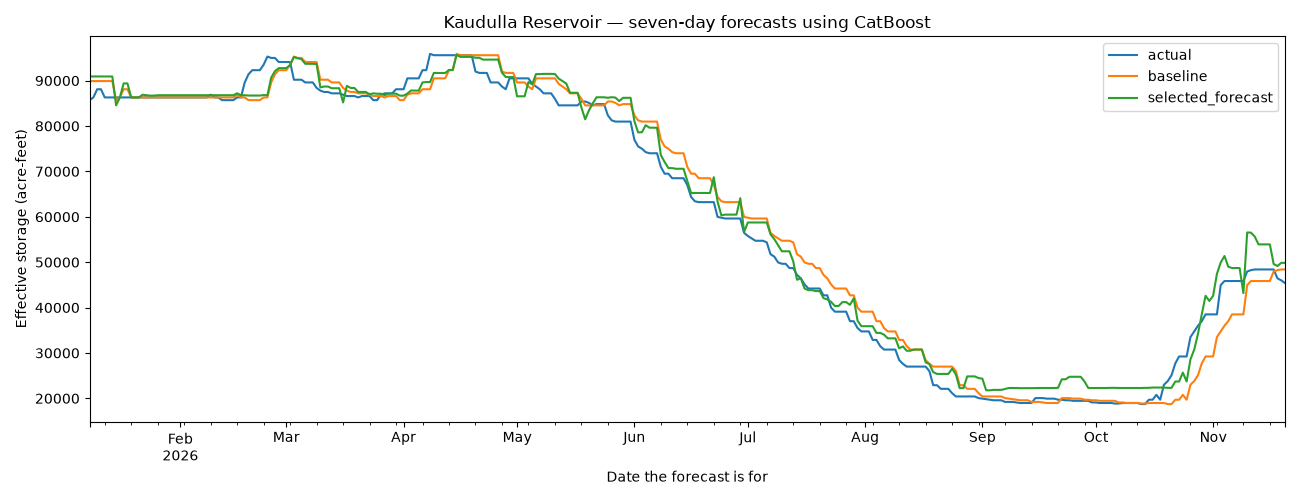

In [ ]:
forecast_rows = pd.DataFrame({
    "forecast_date": test["period"],
    "target_date": test["period"] + pd.Timedelta(days=7),
    "actual": test[target],
    "baseline": test_predictions["Baseline"],
    "selected_forecast": test_predictions[selected_name]
}).sort_values("target_date")

forecast_rows["absolute_error"] = (
    forecast_rows["actual"] - forecast_rows["selected_forecast"]
).abs()

ax = forecast_rows.plot(
    x="target_date",
    y=["actual", "baseline", "selected_forecast"],
    figsize=(13, 5),
    title=f"Kaudulla Reservoir — seven-day forecasts using {selected_name}"
)
ax.set_xlabel("Date the forecast is for")
ax.set_ylabel("Effective storage (acre-feet)")
plt.tight_layout()
plt.show()

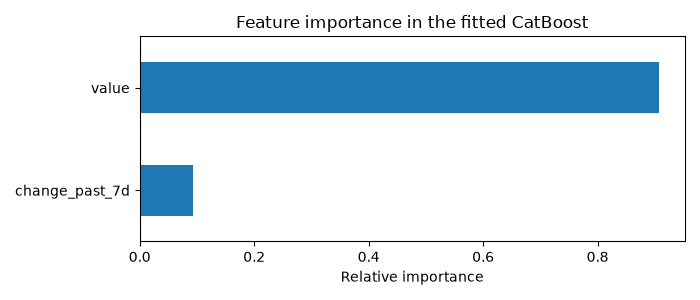

In [ ]:
selected_imp = final_models[selected_name].feature_importances_
forest_importance = pd.Series(
    selected_imp / selected_imp.sum(),
    index=features
).sort_values()

ax = forest_importance.plot.barh(
    figsize=(7, 3),
    title=f"Feature importance in the fitted {selected_name}"
)
ax.set_xlabel("Relative importance")
plt.tight_layout()
plt.show()

In [ ]:
print("Five largest errors from the validation-selected method")
display(forecast_rows.nlargest(5, "absolute_error").round(1))

Five largest errors from the validation-selected method


,forecast_date,target_date,actual,baseline,selected_forecast,absolute_error
2032,2026-10-26,2026-11-02,38500.0,33500,47421.1,8921.1
2040,2026-11-03,2026-11-10,47950.0,44950,56544.7,8594.7
1781,2026-02-17,2026-02-24,95300.0,86300,86783.0,8517.0
2041,2026-11-04,2026-11-11,48250.0,45850,56516.5,8266.5
2042,2026-11-05,2026-11-12,48400.0,45850,55635.0,7235.0


## 10. Saving the Model and Streamlit App
The trained models, evaluation scores, 2026 test predictions, default inputs, `requirements.txt`, and `app.py` are saved to `kaudulla_forecast_app/` and archived as `kaudulla_forecast_app.zip`.


In [ ]:
from pathlib import Path
import joblib
import json
import shutil
import sys

project = Path("kaudulla_forecast_app")
project.mkdir(exist_ok=True)

valid_readings = data.sort_values("period").dropna(subset=["value", "storage_7d_ago"])
history_lookup = {
    row["period"].date().isoformat(): {
        "storage": float(row["value"]),
        "previous_storage": float(row["storage_7d_ago"]),
        "actual_7d": None if pd.isna(row["target_7d"]) else float(row["target_7d"])
    }
    for _, row in valid_readings.iterrows()
}

bundle = {
    "name": selected_name,
    "features": features,
    "model": final_models.get(selected_name),
    "models": final_models,
    "feature_importance": forest_importance.to_dict(),
    "history_lookup": history_lookup
}
joblib.dump(bundle, project / "forecast_model.joblib")

for m_name in final_models:
    forecast_rows[m_name] = test_predictions[m_name]

results.rename_axis("Model").to_csv(project / "model_scores.csv")
forecast_rows.to_csv(project / "test_forecasts.csv", index=False)

latest = valid_readings.iloc[-1]
defaults = {
    "reading_date": latest["period"].date().isoformat(),
    "storage": float(latest["value"]),
    "previous_storage": float(latest["storage_7d_ago"])
}
(project / "defaults.json").write_text(json.dumps(defaults))

In [ ]:
requirements = [
    "streamlit>=1.38.0",
    "pandas>=2.2.0",
    "numpy>=1.26.0",
    "scipy>=1.13.0",
    "scikit-learn>=1.5.0",
    "xgboost>=2.1.0",
    "lightgbm>=4.5.0",
    "catboost>=1.2.7",
    "joblib>=1.4.0",
]
(project / "requirements.txt").write_text("\n".join(requirements) + "\n")

print("Saved selected method:", selected_name)
print("Python version:", f"{sys.version_info.major}.{sys.version_info.minor}")

Saved selected method: CatBoost
Python version: 3.12


In [30]:
%%writefile kaudulla_forecast_app/app.py
from datetime import date, timedelta
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import streamlit as st

ROOT = Path(__file__).parent

st.set_page_config(page_title="Kaudulla Reservoir Forecast", layout="wide")
st.title("Kaudulla Reservoir Forecast")
st.write("Predict effective water storage (acre-feet) seven calendar days after a reading.")

@st.cache_resource
def load_bundle():
    return joblib.load(ROOT / "forecast_model.joblib")

bundle = load_bundle()
defaults = json.loads((ROOT / "defaults.json").read_text())
scores = pd.read_csv(ROOT / "model_scores.csv").set_index("Model")
history = pd.read_csv(ROOT / "test_forecasts.csv", parse_dates=["forecast_date", "target_date"])
history_lookup = bundle.get("history_lookup", {})
all_models = bundle.get("models", {bundle["name"]: bundle["model"]})
features = bundle["features"]

def get_model_importance(model_name):
    m = all_models.get(model_name)
    if m is None or not hasattr(m, "feature_importances_"):
        return None
    arr = np.asarray(m.feature_importances_, dtype=float)
    total = arr.sum()
    if total <= 0:
        return None
    return pd.Series(arr / total, index=features).sort_values()

model_options = list(scores.index)
default_idx = model_options.index(bundle["name"]) if bundle["name"] in model_options else 0

st.subheader("Try a forecast")

col1, col2, col3, col4 = st.columns(4)

with col1:
    selected_model = st.selectbox("Model", options=model_options, index=default_idx)

with col2:
    reading_date = st.date_input(
        "Reading date",
        value=date.fromisoformat(defaults["reading_date"]),
        min_value=date(2020, 10, 8),
        max_value=date(2027, 12, 31)
    )

date_key = reading_date.isoformat()
if date_key in history_lookup:
    default_current = history_lookup[date_key]["storage"]
    default_previous = history_lookup[date_key]["previous_storage"]
else:
    default_current = defaults["storage"]
    default_previous = defaults["previous_storage"]

with col3:
    current = st.number_input(
        f"Storage on {reading_date} (acre-feet)",
        min_value=0.0,
        value=float(default_current),
        step=500.0
    )

with col4:
    previous = st.number_input(
        f"Storage on {reading_date - timedelta(days=7)} (acre-feet)",
        min_value=0.0,
        value=float(default_previous),
        step=500.0
    )

change_past_7d = current - previous
inputs = pd.DataFrame([{
    "value": current,
    "change_past_7d": change_past_7d
}])

if selected_model == "Baseline":
    estimate = current
elif selected_model in all_models and all_models[selected_model] is not None:
    estimate = float(all_models[selected_model].predict(inputs[features])[0])
else:
    estimate = float(bundle["model"].predict(inputs[features])[0])

target_date = reading_date + timedelta(days=7)
baseline_test_mae = float(scores.loc["Baseline", "Test MAE"])
selected_test_mae = float(scores.loc[selected_model, "Test MAE"])
mae_reduction_pct = 100.0 * (baseline_test_mae - selected_test_mae) / baseline_test_mae

m1, m2, m3 = st.columns(3)
with m1:
    st.metric(
        f"Forecast for {target_date}",
        f"{estimate:,.0f} acre-feet",
        delta=f"{estimate - current:+,.0f} vs reading date"
    )
with m2:
    st.metric(
        "Past 7-day change",
        f"{change_past_7d:+,.0f} acre-feet"
    )
with m3:
    st.metric(
        f"{selected_model} Test MAE",
        f"{selected_test_mae:,.1f} acre-feet",
        delta=f"{mae_reduction_pct:+.1f}% vs Baseline"
    )

tab1, tab2, tab3 = st.tabs([
    "2026 Test Forecasts",
    "Model Scores",
    "Feature Importance & Errors"
])

if selected_model == "Baseline":
    plot_col = "baseline"
elif selected_model in history.columns:
    plot_col = selected_model
else:
    plot_col = "selected_forecast"

with tab1:
    chart_df = history.set_index("target_date")[["actual", "baseline"]].copy()
    if selected_model != "Baseline":
        chart_df[selected_model] = history.set_index("target_date")[plot_col]
    st.line_chart(chart_df)

with tab2:
    st.dataframe(scores.round(1), use_container_width=True)
    st.caption("MAE is the average absolute error in acre-feet. Lower is better.")

with tab3:
    c1, c2 = st.columns([1, 1.4])
    with c1:
        imp_series = get_model_importance(selected_model)
        if imp_series is not None:
            st.write(f"**Feature Importance ({selected_model})**")
            st.bar_chart(imp_series.rename("Importance").to_frame())
        else:
            st.write("**Feature Importance**")
            st.caption("Available for single tree-based models (Random Forest, XGBoost, LightGBM, CatBoost).")

    with c2:
        st.write(f"**Top 5 Largest Errors ({selected_model})**")
        err_df = history[["forecast_date", "target_date", "actual", "baseline"]].copy()
        err_df["forecast"] = history[plot_col]
        err_df["absolute_error"] = (err_df["actual"] - err_df["forecast"]).abs()
        top5 = err_df.nlargest(5, "absolute_error").copy()
        top5["forecast_date"] = top5["forecast_date"].dt.strftime("%Y-%m-%d")
        top5["target_date"] = top5["target_date"].dt.strftime("%Y-%m-%d")
        st.dataframe(top5.round(1), use_container_width=True, hide_index=True)

st.caption("Data source: Sri Lanka Irrigation Department, via Macro Lab.")

Writing kaudulla_forecast_app/app.py


In [31]:
import py_compile
from google.colab import files

py_compile.compile(
    str(project / "app.py"),
    cfile="/tmp/kaudulla_app_check.pyc",
    doraise=True
)

loaded = joblib.load(project / "forecast_model.joblib")
sample = test[features].iloc[:1]

if loaded["name"] == "Baseline":
    saved_prediction = sample["value"].iloc[0]
else:
    saved_prediction = loaded["model"].predict(sample)[0]

assert np.isclose(saved_prediction, test_predictions[selected_name].iloc[0])
print("App syntax checked. Saved method reproduced the first test forecast.")

archive = shutil.make_archive("kaudulla_forecast_app", "zip", root_dir=project)
files.download(archive)

App syntax checked. Saved method reproduced the first test forecast.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusion
The simple baseline had the lowest error on the 2025 validation data. Among the machine-learning models, CatBoost performed best on validation, so it was selected for the dashboard. On the 2026 test data, its average error was 2,789.8 acre-feet, which was 10.8% lower than the baseline. LightGBM achieved the lowest test error, showing that the model ranking changed between the two periods.
